## **Crop Yield Prediction Using  Linear Regression**

  Goal: To predict crop yield using Simple and Multiple Linear Regression based on rainfall, soil quality, farm size, sunlight hours, and fertilizer usage.

**Import required libraries**

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


**Load the crop-yield dataset**

In [5]:
# Upload CSV file in Google Colab

from google.colab import files
uploaded = files.upload()

# Read uploaded CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

Saving crop_yield_data.csv to crop_yield_data (2).csv
Dataset loaded successfully!


**Understand the dataset**

In [7]:
# Display first five records

print("First 5 Records:")
display(df.head())

# Display last five records
print("Last 5 Records:")
display(df.tail())

# Dataset dimensions
print("Number of Rows and Columns:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First 5 Records:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
0,1626,9,636,11,1006,404
1,1959,9,73,11,112,115
2,1360,1,352,5,702,231
3,1794,2,948,7,299,537
4,1630,5,884,5,2733,554


Last 5 Records:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
2995,1483,9,78,12,2739,155
2996,804,9,481,4,1898,319
2997,870,1,113,7,2282,129
2998,1352,6,767,11,2901,493
2999,883,7,170,11,485,134


Number of Rows and Columns: (3000, 6)

Column Names:
['rainfall_mm', 'soil_quality_index', 'farm_size_hectares', 'sunlight_hours', 'fertilizer_kg', 'crop_yield']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   rainfall_mm         3000 non-null   int64
 1   soil_quality_index  3000 non-null   int64
 2   farm_size_hectares  3000 non-null   int64
 3   sunlight_hours      3000 non-null   int64
 4   fertilizer_kg       3000 non-null   int64
 5   crop_yield          3000 non-null   int64
dtypes: int64(6)
memory usage: 140.8 KB

Statistical Summary:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1263.095000,5.506667,498.801000,7.995333,1549.450333,328.099000
std,432.371756,2.855172,287.122742,2.621501,814.326919,145.036503
min,500.000000,1.000000,10.000000,4.000000,100.000000,46.000000
25%,896.000000,3.000000,242.000000,6.000000,869.750000,199.000000
50%,1277.000000,6.000000,505.000000,8.000000,1542.000000,332.000000
75%,1636.000000,8.000000,741.000000,10.000000,2225.000000,455.000000
max,2000.000000,10.000000,1000.000000,12.000000,3000.000000,628.000000


**Identify input features and target variable**

In [8]:
# Independent variables (Input Features)

features = [
    'rainfall_mm',
    'soil_quality_index',
    'farm_size_hectares',
    'sunlight_hours',
    'fertilizer_kg'
]

# Dependent variable (Target)
target = 'crop_yield'

X = df[features]
y = df[target]

print("Input Features:")
print(features)

print("\nTarget Variable:")
print(target)

print("\nX Shape:", X.shape)
print("Y Shape:", y.shape)

Input Features:
['rainfall_mm', 'soil_quality_index', 'farm_size_hectares', 'sunlight_hours', 'fertilizer_kg']

Target Variable:
crop_yield

X Shape: (3000, 5)
Y Shape: (3000,)


**Data cleaning**

In [9]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records

print("\nDuplicate Records:")
print(df.duplicated().sum())

# Replace missing numerical values with median

for column in features + [target]:
    df[column] = df[column].fillna(df[column].median())

# Remove duplicate records

df = df.drop_duplicates().reset_index(drop=True)

# Check again

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(df.duplicated().sum())

print("\nCleaned Dataset:")
display(df.head())

Missing Values:
rainfall_mm           0
soil_quality_index    0
farm_size_hectares    0
sunlight_hours        0
fertilizer_kg         0
crop_yield            0
dtype: int64

Duplicate Records:
0

Missing Values After Cleaning:
rainfall_mm           0
soil_quality_index    0
farm_size_hectares    0
sunlight_hours        0
fertilizer_kg         0
crop_yield            0
dtype: int64

Duplicate Records After Cleaning:
0

Cleaned Dataset:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
0,1626,9,636,11,1006,404
1,1959,9,73,11,112,115
2,1360,1,352,5,702,231
3,1794,2,948,7,299,537
4,1630,5,884,5,2733,554


Dataset visualization

Histogram of crop yield

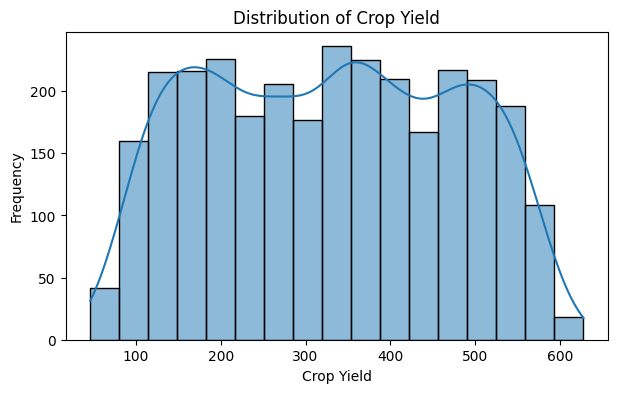

In [10]:
plt.figure(figsize=(7, 4))

sns.histplot(df['crop_yield'], kde=True)

plt.title("Distribution of Crop Yield")
plt.xlabel("Crop Yield")
plt.ylabel("Frequency")

plt.show()

**Boxplot to identify possible outliers**

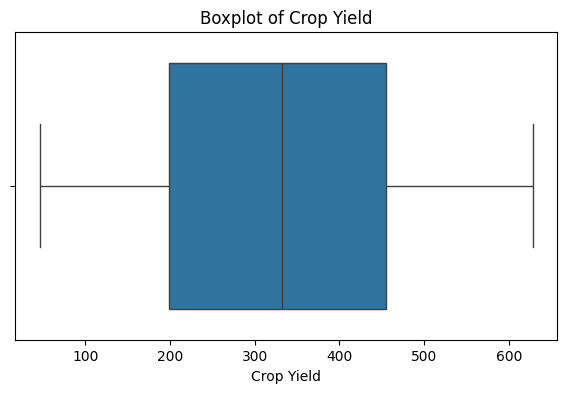

In [11]:
plt.figure(figsize=(7, 4))

sns.boxplot(x=df['crop_yield'])

plt.title("Boxplot of Crop Yield")
plt.xlabel("Crop Yield")

plt.show()

**Scatter plots of input features against target**

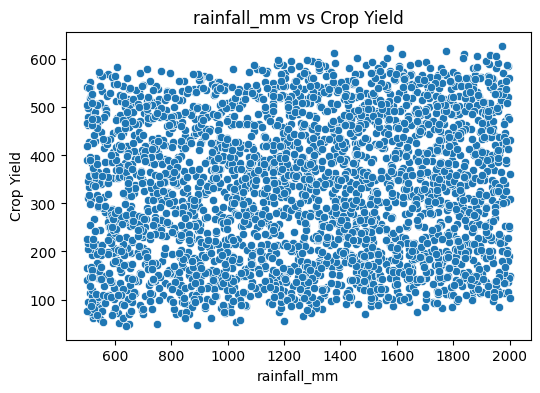

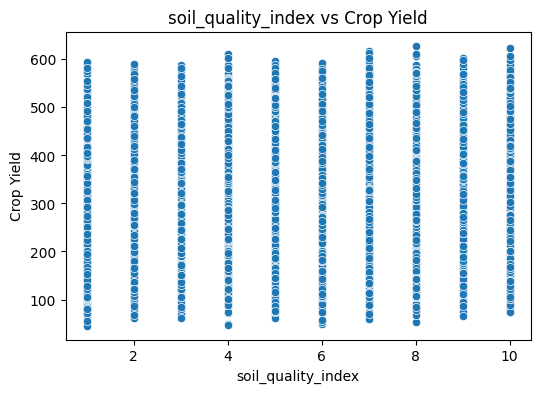

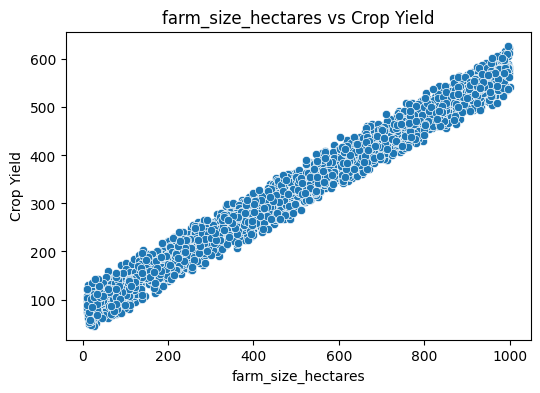

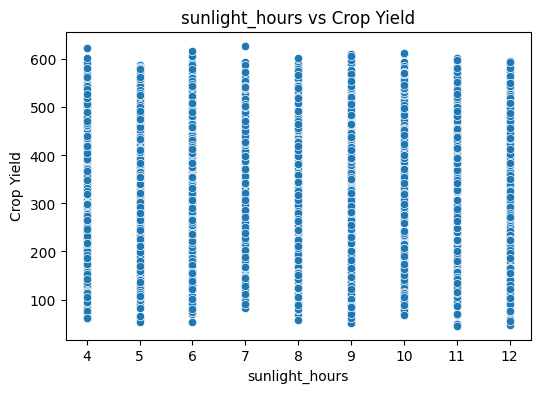

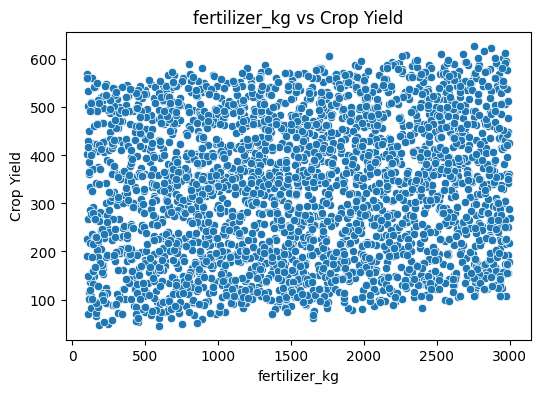

In [12]:
for feature in features:

    plt.figure(figsize=(6, 4))

    sns.scatterplot(data=df, x=feature, y=target)

    plt.title(feature + " vs Crop Yield")
    plt.xlabel(feature)
    plt.ylabel("Crop Yield")

    plt.show()

**Correlation matrix and heatmap**

Correlation Matrix:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
rainfall_mm,1.000000,-0.022198,0.001127,-0.005250,-0.029317,0.086339
soil_quality_index,-0.022198,1.000000,0.005829,0.002187,0.007254,0.043990
farm_size_hectares,0.001127,0.005829,1.000000,-0.010054,-0.008032,0.989201
sunlight_hours,-0.005250,0.002187,-0.010054,1.000000,0.016289,-0.006792
fertilizer_kg,-0.029317,0.007254,-0.008032,0.016289,1.000000,0.102023
crop_yield,0.086339,0.043990,0.989201,-0.006792,0.102023,1.000000


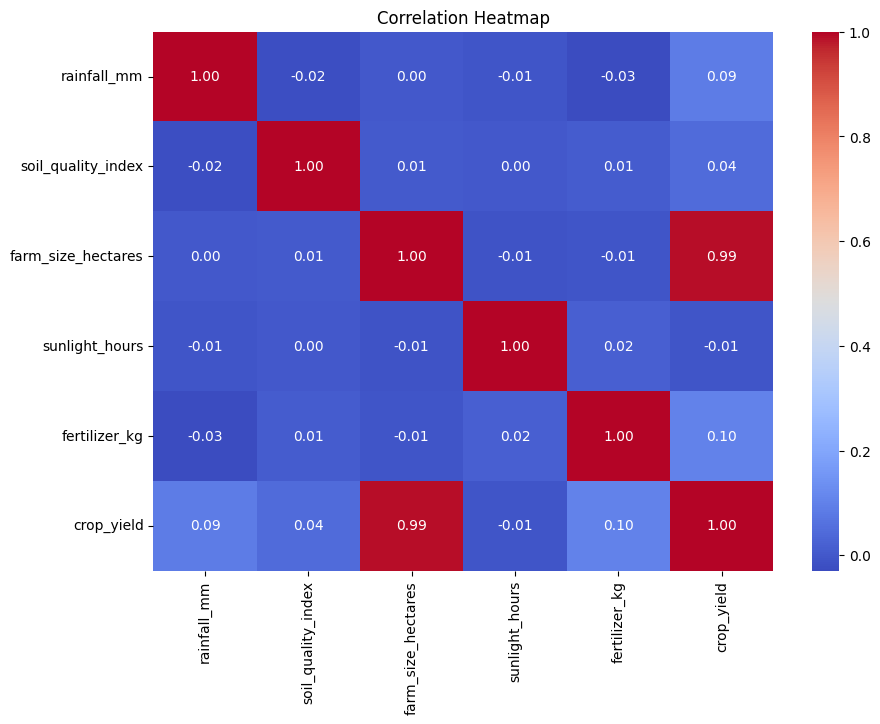

In [13]:
# Calculate correlation

correlation = df[features + [target]].corr()

print("Correlation Matrix:")
display(correlation)

# Plot heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

**Manual calculation using normal equations**

In [14]:
# Select first 6 observations and 2 features

sample = df[
    ['rainfall_mm', 'soil_quality_index', 'crop_yield']
].head(6)

print("Selected 6 Observations:")
display(sample)

# Extract variables

X1 = sample['rainfall_mm'].values
X2 = sample['soil_quality_index'].values
Y = sample['crop_yield'].values

# Create design matrix with intercept column

X_manual = np.column_stack((
    np.ones(len(sample)),
    X1,
    X2
))

print("Design Matrix X:")
print(X_manual)

print("\nTarget Vector Y:")
print(Y)

# Calculate transpose of X

XT = X_manual.T

# Calculate X transpose X

XTX = XT @ X_manual

print("\nX Transpose X:")
print(XTX)

# Calculate X transpose Y

XTY = XT @ Y

print("\nX Transpose Y:")
print(XTY)

# Solve normal equations

B = np.linalg.pinv(XTX) @ XTY

b0, b1, b2 = B

print("\nCalculated Coefficients:")

print("Intercept (b0):", b0)
print("Rainfall Coefficient (b1):", b1)
print("Soil Quality Coefficient (b2):", b2)

print("\nManual Regression Equation:")

print(
    f"Crop Yield = {b0:.4f} "
    f"+ ({b1:.4f} × Rainfall) "
    f"+ ({b2:.4f} × Soil Quality)"
)

Selected 6 Observations:


,rainfall_mm,soil_quality_index,crop_yield
0,1626,9,404
1,1959,9,115
2,1360,1,231
3,1794,2,537
4,1630,5,554
5,1595,4,556


Design Matrix X:
[[1.000e+00 1.626e+03 9.000e+00]
 [1.000e+00 1.959e+03 9.000e+00]
 [1.000e+00 1.360e+03 1.000e+00]
 [1.000e+00 1.794e+03 2.000e+00]
 [1.000e+00 1.630e+03 5.000e+00]
 [1.000e+00 1.595e+03 4.000e+00]]

Target Vector Y:
[404 115 231 537 554 556]

X Transpose X:
[[6.0000000e+00 9.9640000e+03 3.0000000e+01]
 [9.9640000e+03 1.6750518e+07 5.1743000e+04]
 [3.0000000e+01 5.1743000e+04 2.0800000e+02]]

X Transpose Y:
[2.397000e+03 3.949567e+06 1.097000e+04]

Calculated Coefficients:
Intercept (b0): 459.1974850468052
Rainfall Coefficient (b1): 0.018598358400137304
Soil Quality Coefficient (b2): -18.116631779338785

Manual Regression Equation:
Crop Yield = 459.1975 + (0.0186 × Rainfall) + (-18.1166 × Soil Quality)


**Prediction and residual using manual calculation**

In [15]:
# Predict first observation

actual_value = Y[0]

predicted_value = (
    b0 + b1 * X1[0] + b2 * X2[0]
)

# Calculate residual

residual = actual_value - predicted_value

print("Actual Value:", actual_value)
print("Predicted Value:", predicted_value)
print("Residual:", residual)

Actual Value: 404
Predicted Value: 326.38872979137943
Residual: 77.61127020862057


**Verify manual calculation using Linear Regression**

In [16]:
# Create Linear Regression model

manual_model = LinearRegression()

# Train model using same 6 observations and 2 features

manual_model.fit(
    sample[['rainfall_mm', 'soil_quality_index']],
    sample['crop_yield']
)

print("Manual Intercept:", b0)
print("Library Intercept:", manual_model.intercept_)

print("\nManual Coefficients:", [b1, b2])
print("Library Coefficients:", manual_model.coef_)

print("\nManual and Library calculations should be approximately equal.")

Manual Intercept: 459.1974850468052
Library Intercept: 459.19748505275186

Manual Coefficients: [np.float64(0.018598358400137304), np.float64(-18.116631779338785)]
Library Coefficients: [  0.01859836 -18.11663178]

Manual and Library calculations should be approximately equal.


**Split dataset into training and testing data**

In [17]:
# Define X and Y

X = df[features]
y = df[target]

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Data: (2400, 5)
Testing Data: (600, 5)

Training Records: 2400
Testing Records: 600


**Mean baseline model**

In [18]:
# Mean baseline prediction

baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

print("Baseline Mean Prediction:", y_train.mean())

print("\nBaseline R2 Score:",
      r2_score(y_test, baseline_predictions))

Baseline Mean Prediction: 328.08708333333334

Baseline R2 Score: -1.6578155448421228e-07


**Simple Linear Regression**

In [19]:
# Find feature with highest correlation with crop yield

train_corr = X_train.join(y_train).corr()[target]

simple_feature = train_corr.drop(target).abs().idxmax()

print("Selected Feature:", simple_feature)

# Create simple regression model

simple_model = LinearRegression()

# Train model

simple_model.fit(
    X_train[[simple_feature]],
    y_train
)

# Predict test data

simple_predictions = simple_model.predict(
    X_test[[simple_feature]]
)

# Display coefficients

print("\nSimple Regression Intercept:",
      simple_model.intercept_)

print("Simple Regression Coefficient:",
      simple_model.coef_[0])

print("\nSimple Regression R2 Score:",
      r2_score(y_test, simple_predictions))

Selected Feature: farm_size_hectares

Simple Regression Intercept: 78.52683955256245
Simple Regression Coefficient: 0.5003363047821624

Simple Regression R2 Score: 0.9784884123881824


**Simple Linear Regression graph**

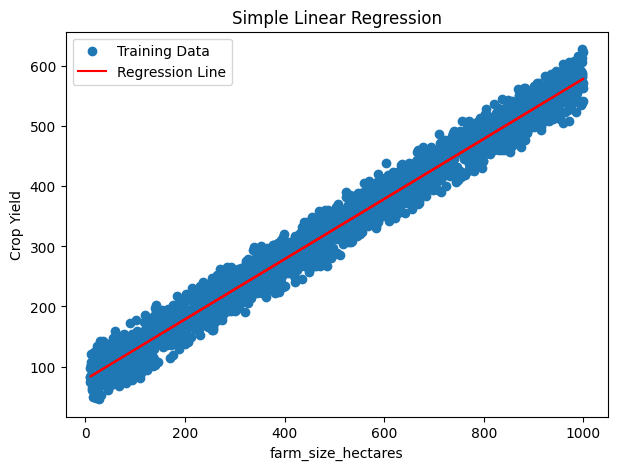

In [20]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_train[simple_feature],
    y_train,
    label="Training Data"
)

plt.plot(
    X_train[simple_feature],
    simple_model.predict(X_train[[simple_feature]]),
    color='red',
    label="Regression Line"
)

plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")

plt.title("Simple Linear Regression")

plt.legend()
plt.show()

**Multiple Linear Regression**

In [21]:
# Create multiple regression model

multiple_model = LinearRegression()

# Train model using all input features

multiple_model.fit(X_train, y_train)

# Predict test data

multiple_predictions = multiple_model.predict(X_test)

print("Multiple Regression Intercept:",
      multiple_model.intercept_)

print("\nMultiple Regression Coefficients:")

for feature, coefficient in zip(
    features,
    multiple_model.coef_
):
    print(feature, ":", coefficient)

Multiple Regression Intercept: -1.933930614117287

Multiple Regression Coefficients:
rainfall_mm : 0.029979326095132215
soil_quality_index : 2.001966619854761
farm_size_hectares : 0.4999905425441692
sunlight_hours : 0.0944605419993554
fertilizer_kg : 0.020001941111278176


**Multiple Linear Regression equation**

In [22]:
equation = f"Crop Yield = {multiple_model.intercept_:.4f}"

for feature, coefficient in zip(
    features,
    multiple_model.coef_
):
    equation += f" + ({coefficient:.4f} × {feature})"

print("Multiple Linear Regression Equation:")
print(equation)

Multiple Linear Regression Equation:
Crop Yield = -1.9339 + (0.0300 × rainfall_mm) + (2.0020 × soil_quality_index) + (0.5000 × farm_size_hectares) + (0.0945 × sunlight_hours) + (0.0200 × fertilizer_kg)


**Interpret regression coefficients**

In [23]:
print("Coefficient Interpretation:\n")

for feature, coefficient in zip(
    features,
    multiple_model.coef_
):

    print(
        f"If {feature} increases by one unit, "
        f"predicted crop yield changes by "
        f"{coefficient:.4f} units, "
        f"holding other features constant."
    )

print("\nIntercept:", multiple_model.intercept_)

print(
    "The intercept represents predicted crop yield "
    "when all input features are zero."
)

Coefficient Interpretation:

If rainfall_mm increases by one unit, predicted crop yield changes by 0.0300 units, holding other features constant.
If soil_quality_index increases by one unit, predicted crop yield changes by 2.0020 units, holding other features constant.
If farm_size_hectares increases by one unit, predicted crop yield changes by 0.5000 units, holding other features constant.
If sunlight_hours increases by one unit, predicted crop yield changes by 0.0945 units, holding other features constant.
If fertilizer_kg increases by one unit, predicted crop yield changes by 0.0200 units, holding other features constant.

Intercept: -1.933930614117287
The intercept represents predicted crop yield when all input features are zero.


**Standardized coefficients**

In [24]:
# Standardize training features and target

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)

y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Train standardized model

standard_model = LinearRegression()

standard_model.fit(
    X_train_scaled,
    y_train_scaled
)

# Display standardized coefficients

standard_coefficients = pd.DataFrame({
    'Feature': features,
    'Standardized Coefficient': standard_model.coef_
})

display(standard_coefficients)

,Feature,Standardized Coefficient
0,rainfall_mm,0.089595
1,soil_quality_index,0.039466
2,farm_size_hectares,0.988520
3,sunlight_hours,0.001707
4,fertilizer_kg,0.112855


**Evaluate model performance**

In [25]:
# Calculate metrics for multiple regression

mae = mean_absolute_error(y_test, multiple_predictions)

mse = mean_squared_error(y_test, multiple_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, multiple_predictions)

print("Multiple Linear Regression Performance")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Multiple Linear Regression Performance
MAE: 0.24319513924681554
MSE: 0.0817605824141062
RMSE: 0.2859380744393901
R2 Score: 0.9999961820468685


**Calculate adjusted R²**

In [26]:
# Number of test observations

n = len(y_test)

# Number of input features

p = len(features)

# Calculate adjusted R2

adjusted_r2 = 1 - (
    (1 - r2) * (n - 1) / (n - p - 1)
)

print("R2 Score:", r2)

print("Adjusted R2 Score:", adjusted_r2)

R2 Score: 0.9999961820468685
Adjusted R2 Score: 0.9999961499092158


**Compare baseline, simple and multiple regression**

In [27]:
# Create comparison table

comparison = pd.DataFrame({

    'Model': [
        'Mean Baseline',
        'Simple Linear Regression',
        'Multiple Linear Regression'
    ],

    'MAE': [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, simple_predictions),
        mean_absolute_error(y_test, multiple_predictions)
    ],

    'MSE': [
        mean_squared_error(y_test, baseline_predictions),
        mean_squared_error(y_test, simple_predictions),
        mean_squared_error(y_test, multiple_predictions)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, simple_predictions)),
        np.sqrt(mean_squared_error(y_test, multiple_predictions))
    ],

    'R2 Score': [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, simple_predictions),
        r2_score(y_test, multiple_predictions)
    ]

})

print("Model Performance Comparison:")

display(comparison.round(4))

Model Performance Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Mean Baseline,126.5143,21414.7720,146.3379,-0.0000
1,Simple Linear Regression,17.6184,460.6657,21.4631,0.9785
2,Multiple Linear Regression,0.2432,0.0818,0.2859,1.0000


**Actual vs predicted values**

In [28]:
prediction_table = pd.DataFrame({

    'Actual Crop Yield': y_test.values,

    'Predicted Crop Yield': multiple_predictions,

    'Residual': y_test.values - multiple_predictions

})

print("Actual and Predicted Values:")

display(prediction_table.head(10).round(2))

Actual and Predicted Values:


,Actual Crop Yield,Predicted Crop Yield,Residual
0,181,181.10,-0.10
1,309,308.73,0.27
2,291,290.70,0.30
3,172,172.07,-0.07
4,261,261.19,-0.19
5,417,416.99,0.01
6,491,491.14,-0.14
7,163,162.66,0.34
8,368,367.64,0.36
9,397,397.18,-0.18


 **Residual plot**

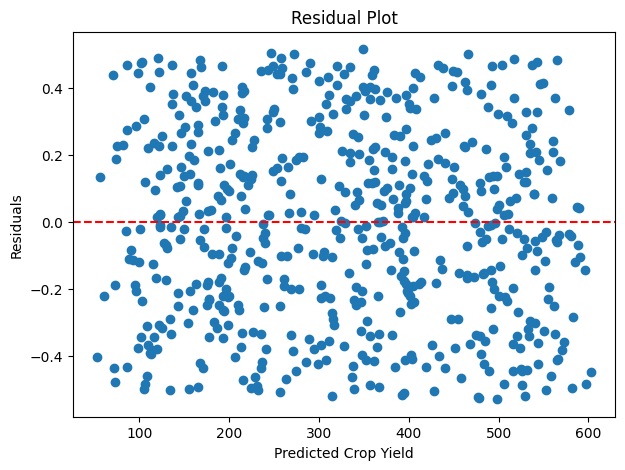

In [29]:
residuals = y_test - multiple_predictions

plt.figure(figsize=(7, 5))

plt.scatter(
    multiple_predictions,
    residuals
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Crop Yield")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

**Histogram of residuals**

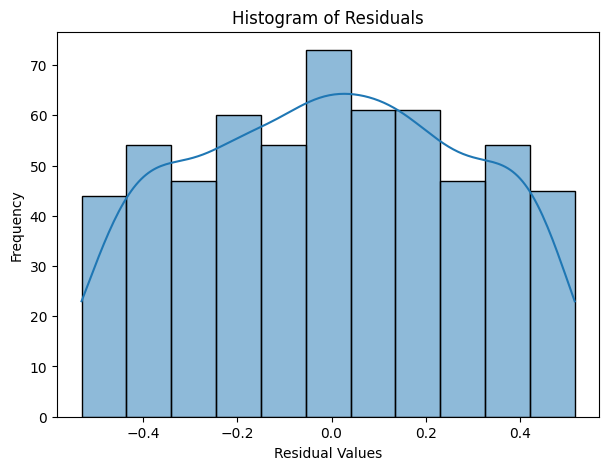

In [30]:
plt.figure(figsize=(7, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Histogram of Residuals")

plt.xlabel("Residual Values")
plt.ylabel("Frequency")

plt.show()

**Actual vs predicted graph**

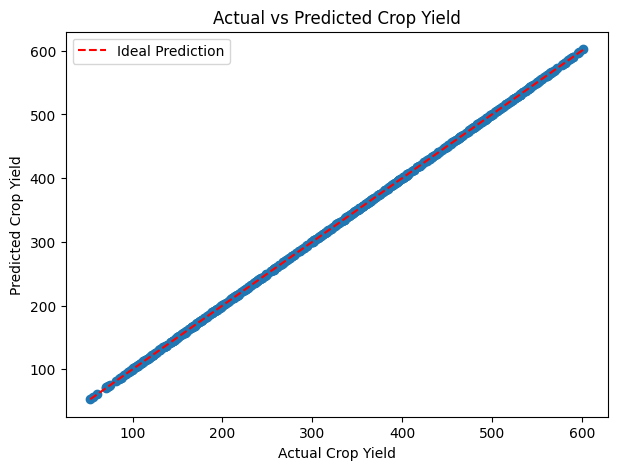

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    multiple_predictions
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label="Ideal Prediction"
)

plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")

plt.title("Actual vs Predicted Crop Yield")

plt.legend()
plt.show()

**Multicollinearity using VIF**

In [32]:
# Calculate VIF for each input feature

vif_data = pd.DataFrame()

vif_data['Feature'] = features

vif_data['VIF'] = [
    variance_inflation_factor(
        X_train.values,
        i
    )
    for i in range(len(features))
]

print("Variance Inflation Factor:")

display(vif_data.round(3))

Variance Inflation Factor:


,Feature,VIF
0,rainfall_mm,1.002
1,soil_quality_index,1.000
2,farm_size_hectares,1.000
3,sunlight_hours,1.000
4,fertilizer_kg,1.001


**Interpret VIF values**

In [33]:
for index, row in vif_data.iterrows():

    feature = row['Feature']
    vif = row['VIF']

    if vif < 5:
        print(feature, ": No strong VIF concern.")

    elif vif < 10:
        print(feature, ": Possible multicollinearity.")

    else:
        print(feature, ": High multicollinearity concern.")

rainfall_mm : No strong VIF concern.
soil_quality_index : No strong VIF concern.
farm_size_hectares : No strong VIF concern.
sunlight_hours : No strong VIF concern.
fertilizer_kg : No strong VIF concern.


**Check regression assumptions**

In [34]:
print("REGRESSION ASSUMPTIONS")

print("\n1. Linearity:")
print("Check the scatter plots for approximately linear relationships.")

print("\n2. Independence:")
print("Errors should be independent of each other. This needs knowledge of how the observations were collected.")

print("\n3. Homoscedasticity:")
print("Residual plot should show approximately constant spread around zero.")

print("\n4. Normality:")
print("Residual histogram should look approximately symmetric and bell-shaped.")

print("\n5. No Severe Multicollinearity:")
print("VIF values should not show severe multicollinearity.")

REGRESSION ASSUMPTIONS

1. Linearity:
Check the scatter plots for approximately linear relationships.

2. Independence:
Errors should be independent of each other. This needs knowledge of how the observations were collected.

3. Homoscedasticity:
Residual plot should show approximately constant spread around zero.

4. Normality:
Residual histogram should look approximately symmetric and bell-shaped.

5. No Severe Multicollinearity:
VIF values should not show severe multicollinearity.


**Predict a new crop yield**

In [35]:
# Create a new observation

new_data = pd.DataFrame({

    'rainfall_mm': [1500],

    'soil_quality_index': [7],

    'farm_size_hectares': [5],

    'sunlight_hours': [8],

    'fertilizer_kg': [500]

})

print("New Input Data:")

display(new_data)

# Check feature ranges

for feature in features:

    minimum = X_train[feature].min()

    maximum = X_train[feature].max()

    value = new_data[feature].iloc[0]

    if value < minimum or value > maximum:

        print("Warning:", feature, "is outside training range.")

# Predict crop yield

new_prediction = multiple_model.predict(new_data)

print("\nPredicted Crop Yield:", round(new_prediction[0], 2))

New Input Data:


,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg
0,1500,7,5,8,500



Predicted Crop Yield: 70.31


**Final conclusion**

In [36]:
print("CONCLUSION")

print(
    "Multiple Linear Regression was used to predict crop yield "
    "using rainfall, soil quality, farm size, sunlight hours "
    "and fertilizer quantity."
)

print(
    "The model was compared with a mean baseline and "
    "Simple Linear Regression."
)

print(
    "MAE, MSE, RMSE, R2 and Adjusted R2 were used "
    "to evaluate the model."
)

print(
    "Correlation analysis and VIF were used to investigate "
    "multicollinearity."
)

print(
    "Residual plots and a histogram were used to examine "
    "the model errors and regression assumptions."
)

print(
    "The model provides an estimated crop yield, but actual yield "
    "may also depend on temperature, crop type, irrigation, "
    "weather conditions and other factors."
)

CONCLUSION
Multiple Linear Regression was used to predict crop yield using rainfall, soil quality, farm size, sunlight hours and fertilizer quantity.
The model was compared with a mean baseline and Simple Linear Regression.
MAE, MSE, RMSE, R2 and Adjusted R2 were used to evaluate the model.
Correlation analysis and VIF were used to investigate multicollinearity.
Residual plots and a histogram were used to examine the model errors and regression assumptions.
The model provides an estimated crop yield, but actual yield may also depend on temperature, crop type, irrigation, weather conditions and other factors.


# **Decision Log**

1. **Problem Framing:**
   The objective is to predict crop yield using multiple agricultural factors.

2. **Dataset Selection:**
   Crop yield dataset containing 200 observations and five input features.

3. **Features Selected:**
   - Rainfall
   - Soil Quality
   - Farm Size
   - Sunlight Hours
   - Fertilizer Quantity

4. **Target Variable:**
   Crop Yield.

5. **Data Cleaning:**
   Missing numerical values were handled using median imputation.
   Duplicate records were removed.

6. **Train-Test Split:**
   The dataset was divided into 80% training and 20% testing data.

7. **Model Selection:**
   Simple Linear Regression and Multiple Linear Regression were compared.

8. **Model Evaluation:**
   MAE, MSE, RMSE, R2 and Adjusted R2 were calculated.

9. **Assumption Checking:**
   Correlation, VIF, residual plot and residual histogram were used.

10. **Limitations:**
    Crop yield may also depend on temperature, crop variety,
    irrigation, pests and other environmental factors.